PROJECT NAME: INSURANCE CLAIM PREDICTIONS

PROJECT TYPE: MACHINE LEARNING-SUPERVISED LEARNING(BINARY CLASSIFICATION)

CONTRIBUTION: INDIVIDUAL

PROJECT SUMMARY:

Insurance Claim Prediction is a supervised machine learning classification project designed to predict whether an insurance policyholder is likely to make an insurance claim. The project uses customer and policy-related information from the insurance dataset to train machine learning models.

The data is preprocessed by handling missing values, removing unnecessary attributes, and dividing the dataset into training and testing sets. Three classification algorithms — Logistic Regression, Random Forest, and XGBoost — are implemented and compared using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

The main objective of this project is to identify patterns in insurance data and develop a model that can effectively predict potential claims. The comparison of different algorithms helps determine their performance and demonstrates how machine learning can support data-driven insurance claim analysis and risk assessment.

GITHUB LINK:
https://github.com/nandhithasekar07-ux/INSURANCE-CLAIM-PREDICTION.git

PROBLEM STATEMENT:

Insurance companies handle a large amount of customer and policy-related data to assess the possibility of insurance claims. Manually analyzing this data can be time-consuming and may make it difficult to identify patterns associated with potential claims.

The Insurance Claim Prediction project aims to develop a machine learning-based system that can analyze available insurance data and predict whether a policyholder is likely to make an insurance claim or not. Three supervised classification algorithms — Logistic Regression, Random Forest, and XGBoost — are used and compared based on their performance.

The system helps demonstrate how machine learning can be applied to insurance data for claim prediction, risk analysis, and data-driven decision-making.

IMPORT LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

In [2]:
!pip install xgboost-q

ERROR: Could not find a version that satisfies the requirement xgboost-q (from versions: none)
ERROR: No matching distribution found for xgboost-q


LOAD DATASET

In [4]:
data=pd.read_csv('/content/train.csv')

In [5]:
data

,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,...,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,7,0,2,2,5,1,0,0,1,0,...,9.0,1.0,5.0,8.0,0.0,1.0,1.0,0.0,0.0,1.0
1,9,0,1,1,7,0,0,0,0,1,...,3.0,1.0,1.0,9.0,0.0,1.0,1.0,0.0,1.0,0.0
2,13,0,5,4,9,1,0,0,0,1,...,4.0,2.0,7.0,7.0,0.0,1.0,1.0,0.0,1.0,0.0
3,16,0,0,1,2,0,0,1,0,0,...,2.0,2.0,4.0,9.0,0.0,0.0,0.0,0.0,0.0,0.0
4,17,0,0,2,0,1,0,1,0,0,...,3.0,1.0,1.0,3.0,0.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113500,284004,0,0,1,5,1,0,0,1,0,...,8.0,0.0,0.0,7.0,0.0,0.0,0.0,0.0,1.0,0.0
113501,284005,0,1,2,1,0,6,0,0,1,...,3.0,2.0,2.0,6.0,0.0,1.0,0.0,1.0,1.0,0.0
113502,284006,0,1,1,1,1,0,0,0,0,...,6.0,1.0,2.0,5.0,0.0,1.0,0.0,1.0,0.0,0.0
113503,284008,0,5,1,6,0,0,1,0,0,...,5.0,2.0,0.0,6.0,0.0,1.0,0.0,0.0,0.0,0.0


BASIC CHECKS

In [6]:
data.head()

,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,...,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,7,0,2,2,5,1,0,0,1,0,...,9.0,1.0,5.0,8.0,0.0,1.0,1.0,0.0,0.0,1.0
1,9,0,1,1,7,0,0,0,0,1,...,3.0,1.0,1.0,9.0,0.0,1.0,1.0,0.0,1.0,0.0
2,13,0,5,4,9,1,0,0,0,1,...,4.0,2.0,7.0,7.0,0.0,1.0,1.0,0.0,1.0,0.0
3,16,0,0,1,2,0,0,1,0,0,...,2.0,2.0,4.0,9.0,0.0,0.0,0.0,0.0,0.0,0.0
4,17,0,0,2,0,1,0,1,0,0,...,3.0,1.0,1.0,3.0,0.0,0.0,0.0,1.0,1.0,0.0


In [7]:
data.tail()

,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,...,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
113500,284004,0,0,1,5,1,0,0,1,0,...,8.0,0.0,0.0,7.0,0.0,0.0,0.0,0.0,1.0,0.0
113501,284005,0,1,2,1,0,6,0,0,1,...,3.0,2.0,2.0,6.0,0.0,1.0,0.0,1.0,1.0,0.0
113502,284006,0,1,1,1,1,0,0,0,0,...,6.0,1.0,2.0,5.0,0.0,1.0,0.0,1.0,0.0,0.0
113503,284008,0,5,1,6,0,0,1,0,0,...,5.0,2.0,0.0,6.0,0.0,1.0,0.0,0.0,0.0,0.0
113504,284009,0,2,1,6,1,0,0,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113505 entries, 0 to 113504
Data columns (total 59 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              113505 non-null  int64  
 1   target          113505 non-null  int64  
 2   ps_ind_01       113505 non-null  int64  
 3   ps_ind_02_cat   113505 non-null  int64  
 4   ps_ind_03       113505 non-null  int64  
 5   ps_ind_04_cat   113505 non-null  int64  
 6   ps_ind_05_cat   113505 non-null  int64  
 7   ps_ind_06_bin   113505 non-null  int64  
 8   ps_ind_07_bin   113505 non-null  int64  
 9   ps_ind_08_bin   113505 non-null  int64  
 10  ps_ind_09_bin   113505 non-null  int64  
 11  ps_ind_10_bin   113505 non-null  int64  
 12  ps_ind_11_bin   113505 non-null  int64  
 13  ps_ind_12_bin   113505 non-null  int64  
 14  ps_ind_13_bin   113505 non-null  int64  
 15  ps_ind_14       113505 non-null  int64  
 16  ps_ind_15       113505 non-null  int64  
 17  ps_ind_16_

In [9]:
data.describe()

,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,...,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
count,113505.000000,113505.000000,113505.000000,113505.000000,113505.000000,113505.000000,113505.000000,113505.000000,113505.000000,113505.000000,...,113504.000000,113504.000000,113504.000000,113504.000000,113504.000000,113504.000000,113504.000000,113504.000000,113504.000000,113504.000000
mean,142121.578873,0.036765,1.904639,1.356575,4.433584,0.416924,0.402114,0.393199,0.254976,0.164689,...,5.446002,1.444381,2.875828,7.529127,0.122383,0.629696,0.555152,0.287091,0.351292,0.153554
std,81945.650396,0.188185,1.985334,0.663296,2.701490,0.493338,1.343726,0.488462,0.435849,0.370901,...,2.331929,1.203433,1.694077,2.751751,0.327729,0.482888,0.496951,0.452407,0.477376,0.360522
min,7.000000,0.000000,0.000000,-1.000000,0.000000,-1.000000,-1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,71099.000000,0.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,4.000000,1.000000,2.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,142268.000000,0.000000,1.000000,1.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,5.000000,1.000000,3.000000,7.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000
75%,212950.000000,0.000000,3.000000,2.000000,6.000000,1.000000,0.000000,1.000000,1.000000,0.000000,...,7.000000,2.000000,4.000000,9.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000
max,284009.000000,1.000000,7.000000,4.000000,11.000000,1.000000,6.000000,1.000000,1.000000,1.000000,...,19.000000,10.000000,12.000000,22.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [10]:
data.shape

(113505, 59)

In [11]:
data.isnull().sum()

,0
id,0
target,0
ps_ind_01,0
ps_ind_02_cat,0
ps_ind_03,0
ps_ind_04_cat,0
ps_ind_05_cat,0
ps_ind_06_bin,0
ps_ind_07_bin,0
ps_ind_08_bin,0


In [12]:
data.duplicated().sum()

np.int64(0)

CHECK TARGET DISTRIBUTION

In [13]:
print(data['target'].value_counts(normalize=True)*100)

target
0    96.32351
1     3.67649
Name: proportion, dtype: float64


VISUALIZE TARGET DISTRIBUTION

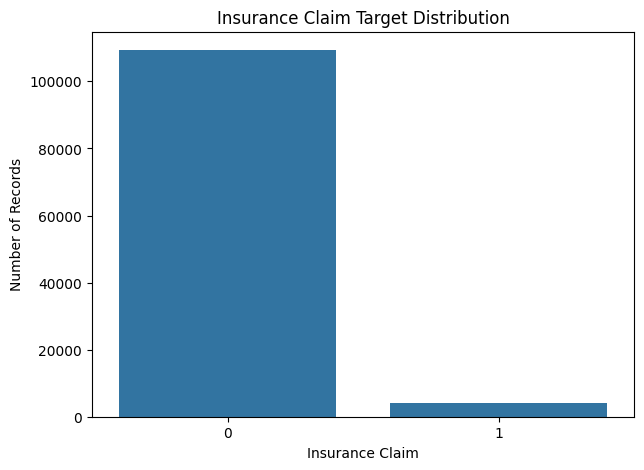

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(x="target", data=data)

plt.title("Insurance Claim Target Distribution")
plt.xlabel("Insurance Claim")
plt.ylabel("Number of Records")

plt.show()

The target variable is highly imbalanced because the majority of records belong to class 0, while only a small percentage belong to class 1.

SEPERATE FEATURE AND TARGET

In [15]:
X = data.drop(columns=["target", "id"])
y = data["target"]

Why remove id?

id is only an identifier. It doesn't represent a meaningful insurance characteristic, so we don't want the models learning from it.

CHECK FEATURE TYPES

In [16]:
print("Integer columns:", X.select_dtypes(include=["int64"]).shape[1])
print("Float columns:", X.select_dtypes(include=["float64"]).shape[1])
print("Object columns:", X.select_dtypes(include=["object"]).shape[1])

Integer columns: 30
Float columns: 27
Object columns: 0


Dataset is numeric,so we don't need one-hot encoding.

TRAIN TEST SPLIT

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training data: (90804, 57)
Testing data: (22701, 57)

Training target distribution:
target
0    0.96324
1    0.03676
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.963217
1    0.036783
Name: proportion, dtype: float64


Why stratify=y?

Because your target is imbalanced.
stratify=y makes sure the training and testing datasets maintain approximately the same proportion of claim/no-claim records.

LOGISTIC REGRESSION

In [18]:
print("NaN values in X:")
print(X.isna().sum().sum())

print("\nNaN values by column:")
print(X.isna().sum()[X.isna().sum() > 0])

print("\nInfinite values:")
print(np.isinf(X.select_dtypes(include=np.number)).sum().sum())

NaN values in X:
22

NaN values by column:
ps_car_14         1
ps_car_15         1
ps_calc_01        1
ps_calc_02        1
ps_calc_03        1
ps_calc_04        1
ps_calc_05        1
ps_calc_06        1
ps_calc_07        1
ps_calc_08        1
ps_calc_09        1
ps_calc_10        1
ps_calc_11        1
ps_calc_12        1
ps_calc_13        1
ps_calc_14        1
ps_calc_15_bin    1
ps_calc_16_bin    1
ps_calc_17_bin    1
ps_calc_18_bin    1
ps_calc_19_bin    1
ps_calc_20_bin    1
dtype: int64

Infinite values:
0


In [19]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("Missing values handled successfully!")
print("Training shape:", X_train_imputed.shape)
print("Testing shape:", X_test_imputed.shape)

Missing values handled successfully!
Training shape: (90804, 57)
Testing shape: (22701, 57)


In [20]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Scaling completed!")

Scaling completed!


In [21]:
logistic_model = LogisticRegression(class_weight="balanced",max_iter=1000,random_state=42)

logistic_model.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [22]:
y_pred_lr = logistic_model.predict(X_test_scaled)

y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

In [23]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_auc = roc_auc_score(y_test, y_prob_lr)

print("LOGISTIC REGRESSION RESULTS")
print("--------------------------------")
print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)
print("ROC-AUC  :", lr_auc)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

LOGISTIC REGRESSION RESULTS
--------------------------------
Accuracy : 0.6261838685520462
Precision: 0.051681706316652996
Recall   : 0.5281437125748503
F1 Score : 0.09415029888983775
ROC-AUC  : 0.6023961406739252

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.63      0.76     21866
           1       0.05      0.53      0.09       835

    accuracy                           0.63     22701
   macro avg       0.51      0.58      0.43     22701
weighted avg       0.94      0.63      0.74     22701



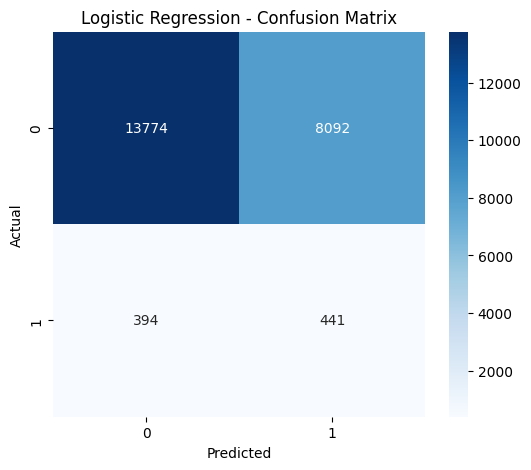

In [24]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr,annot=True,fmt="d",cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

RANDOM FOREST

In [25]:
rf_model = RandomForestClassifier(n_estimators=200,max_depth=15,min_samples_split=10,class_weight="balanced",random_state=42,n_jobs=-1)

rf_model.fit(X_train_imputed, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=15,
                       min_samples_split=10, n_estimators=200, n_jobs=-1,
                       random_state=42)

In [26]:
y_pred_rf = rf_model.predict(X_test_imputed)

y_prob_rf = rf_model.predict_proba(X_test_imputed)[:, 1]

In [27]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_auc = roc_auc_score(y_test, y_prob_rf)

print("RANDOM FOREST RESULTS")
print("--------------------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)
print("ROC-AUC  :", rf_auc)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

RANDOM FOREST RESULTS
--------------------------------
Accuracy : 0.9629531738689926
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0
ROC-AUC  : 0.5646029079680208

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     21866
           1       0.00      0.00      0.00       835

    accuracy                           0.96     22701
   macro avg       0.48      0.50      0.49     22701
weighted avg       0.93      0.96      0.95     22701



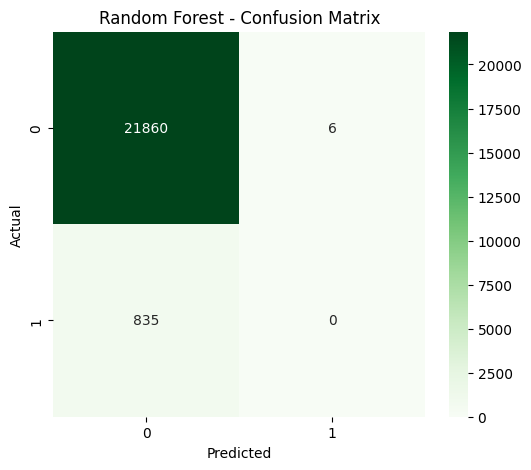

In [28]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf,annot=True,fmt="d",cmap="Greens")

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

XGBOOST

XGBOOST is particulary useful for this type of structured/tabular dataset.

In [29]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

Negative samples: 87466
Positive samples: 3338
Scale Pos Weight: 26.203115638106652


This is automaticallu calculates the appropriate imbalance ratio from training data

In [30]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [31]:
y_pred_xgb = xgb_model.predict(X_test_imputed)

y_prob_xgb = xgb_model.predict_proba(X_test_imputed)[:, 1]

In [32]:
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)
xgb_auc = roc_auc_score(y_test, y_prob_xgb)

print("XGBOOST RESULTS")
print("--------------------------------")
print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1 Score :", xgb_f1)
print("ROC-AUC  :", xgb_auc)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBOOST RESULTS
--------------------------------
Accuracy : 0.8333553587947667
Precision: 0.05921052631578947
Recall   : 0.237125748502994
F1 Score : 0.09475951184493898
ROC-AUC  : 0.5910229207732893

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.86      0.91     21866
           1       0.06      0.24      0.09       835

    accuracy                           0.83     22701
   macro avg       0.51      0.55      0.50     22701
weighted avg       0.93      0.83      0.88     22701



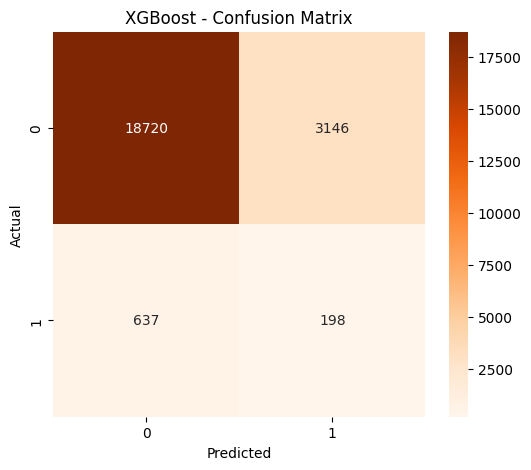

In [33]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_xgb,annot=True,fmt="d",cmap="Oranges")

plt.title("XGBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

FINAL MODEL COMPARISON

In [34]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        lr_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],

    "Precision": [
        lr_precision,
        rf_precision,
        xgb_precision
    ],

    "Recall": [
        lr_recall,
        rf_recall,
        xgb_recall
    ],

    "F1 Score": [
        lr_f1,
        rf_f1,
        xgb_f1
    ],

    "ROC-AUC": [
        lr_auc,
        rf_auc,
        xgb_auc
    ]
})

results = results.round(4)

print("MODEL COMPARISON")
display(results)

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6262,0.0517,0.5281,0.0942,0.6024
1,Random Forest,0.9630,0.0000,0.0000,0.0000,0.5646
2,XGBoost,0.8334,0.0592,0.2371,0.0948,0.5910


ROC CURVE COMPARISION

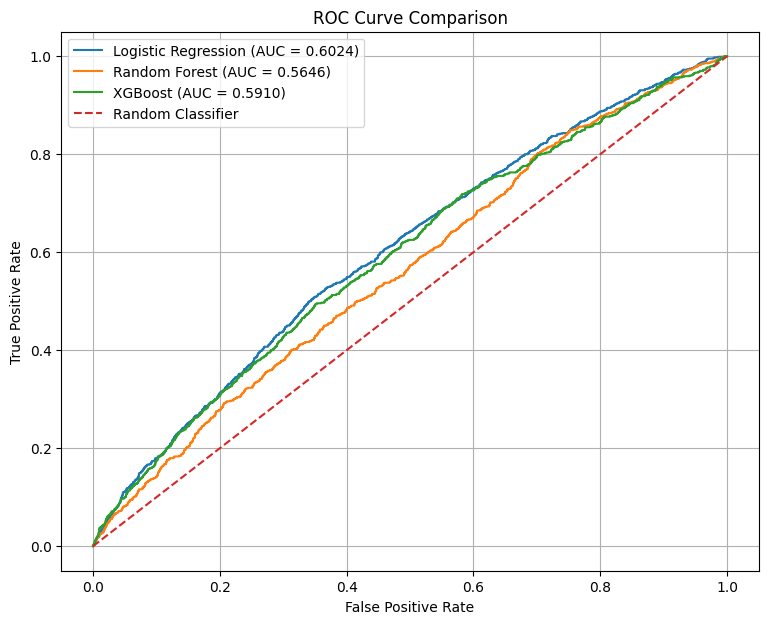

In [35]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {lr_auc:.4f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {rf_auc:.4f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC = {xgb_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()

plt.show()

CONCLUSION:



The Insurance Claim Prediction project demonstrates the use of machine learning techniques to predict whether an insurance policyholder is likely to make a claim. The dataset was preprocessed by handling missing values, removing unnecessary attributes, splitting the data into training and testing sets, and applying feature scaling where required.

Three machine learning algorithms — Logistic Regression, Random Forest, and XGBoost — were implemented and compared using evaluation metrics such as Accuracy, Precision, Recall, F1-Score, and ROC-AUC. Since the dataset contains an imbalanced target variable, multiple evaluation metrics were considered rather than relying only on accuracy.

The comparison helps identify how different classification algorithms perform in predicting insurance claims. This project shows that machine learning can be effectively applied to insurance data to support claim-risk prediction, data-driven decision-making, and improved analysis of policyholder information. Further improvements can be made through hyperparameter tuning, feature selection, and advanced ensemble techniques to enhance the prediction performance.